# 04 · Optimización de hiperparámetros del detector YOLO11-s (Workshop S5)

**SIRAP – Proyecto Integrador en IA (MIAR0545)** · Eduardo Alejandro Ceballos Jijón · Christian Xavier Valle Maridueña

Este notebook estudia **cuánto y cómo** influye cada hiperparámetro del entrenamiento en el mAP del detector:

1. búsqueda bayesiana (TPE, Optuna) con corridas cortas y comparables;
2. **ranking de importancia** (fANOVA y permutación sobre un *random forest* sustituto);
3. **partial dependence plots** 1D y 2D (interacciones);
4. reentrenamiento de la mejor configuración con el protocolo completo y comparación **antes / después en *test***.

Todo se guarda en `MyDrive/proyecto_integrador_placas/optimizacion/`; si la sesión se cae, el estudio de Optuna
continúa desde el último *trial* (base SQLite en Drive). Requiere GPU (T4) y el Secret `ROBOFLOW_API_KEY`.
Documentación: `docs/optimizacion.md`.

In [1]:
!pip install -q "ultralytics==8.4.177" "roboflow==1.7.1" "optuna>=4.0" scikit-learn

In [2]:
import json, os, shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import torch
from ultralytics import YOLO

def get_secret(name):
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

WORK_DIR = Path("/content/proyecto_integrador_placas")
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = Path("/content/drive/MyDrive/proyecto_integrador_placas")
except ImportError:
    pass
OPT_DIR = WORK_DIR / "optimizacion"
FIG_DIR = OPT_DIR / "figuras"
for d in (OPT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no disponible")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Mounted at /content/drive
GPU: Tesla T4


## 1. Dataset
El mismo dataset y los mismos splits que el entrenamiento del modelo entregado (Roboflow v11), copiados al disco
local de Colab.

In [3]:
RF_WORKSPACE, RF_PROJECT, RF_VERSION = "roboflow-universe-projects", "license-plate-recognition-rxg4e", 11
DATASET_DIR = Path("/content/datasets") / f"{RF_PROJECT}-v{RF_VERSION}"
if not (DATASET_DIR / "data.yaml").exists():
    from roboflow import Roboflow
    Roboflow(api_key=get_secret("ROBOFLOW_API_KEY")).workspace(RF_WORKSPACE).project(RF_PROJECT) \
        .version(RF_VERSION).download("yolov11", location=str(DATASET_DIR))
import yaml
cfg = yaml.safe_load((DATASET_DIR / "data.yaml").read_text())
for split, folder in (("train", "train"), ("val", "valid"), ("test", "test")):
    cfg[split] = str(DATASET_DIR / folder / "images")
cfg["path"] = str(DATASET_DIR)
DATA_YAML = DATASET_DIR / "data_abs.yaml"
DATA_YAML.write_text(yaml.safe_dump(cfg))
print(cfg["names"], "→", DATA_YAML)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/license-plate-recognition-rxg4e-v11 in yolov11:: 100%|██████████| 20262/20262 [00:02<00:00, 7299.09it/s]


['License_Plate'] → /content/datasets/license-plate-recognition-rxg4e-v11/data_abs.yaml


## 2. Espacio de búsqueda y función objetivo

Corridas **cortas y comparables**: 10 épocas, 30 % de *train*, semilla 0. Se fija `optimizer="AdamW"`: con
`"auto"` Ultralytics ignora `lr0`.

In [4]:
SEARCH_EPOCHS, SEARCH_FRACTION, N_TRIALS, SEED = 10, 0.30, 24, 0
BASE = {"lr0": 0.002, "weight_decay": 0.0005, "imgsz": 640, "batch": 16, "mosaic": 1.0, "hsv_v": 0.4, "cos_lr": False}

def suggest(trial):
    return {
        "lr0": trial.suggest_float("lr0", 1e-4, 1e-2, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True),
        "imgsz": trial.suggest_categorical("imgsz", [512, 640, 768]),
        "batch": trial.suggest_categorical("batch", [8, 16, 32]),
        "mosaic": trial.suggest_float("mosaic", 0.0, 1.0),
        "hsv_v": trial.suggest_float("hsv_v", 0.0, 0.8),
        "cos_lr": trial.suggest_categorical("cos_lr", [False, True]),
    }

def train_short(params, name):
    model = YOLO("yolo11s.pt")
    model.train(data=str(DATA_YAML), epochs=SEARCH_EPOCHS, fraction=SEARCH_FRACTION, seed=SEED, deterministic=True,
                optimizer="AdamW", workers=2, project=str(OPT_DIR / "runs"), name=name, exist_ok=True,
                plots=False, verbose=False, **params)
    metrics = model.val(data=str(DATA_YAML), split="val", imgsz=params["imgsz"], verbose=False, plots=False)
    return float(metrics.box.map), float(metrics.box.map50)

def objective(trial):
    params = suggest(trial)
    map50_95, map50 = train_short(params, f"trial_{trial.number:03d}")
    trial.set_user_attr("map50", map50)
    torch.cuda.empty_cache()
    return map50_95

In [5]:
study = optuna.create_study(
    study_name="sirap_yolo11s", direction="maximize", load_if_exists=True,
    storage=f"sqlite:///{OPT_DIR / 'optuna.db'}",
    sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=6))
if not any(t.params == BASE for t in study.trials):
    study.enqueue_trial(BASE)  # la configuración base también entra al estudio, para comparar en igualdad
remaining = N_TRIALS - len([t for t in study.trials if t.state.is_finished()])
if remaining > 0:
    study.optimize(objective, n_trials=remaining, gc_after_trial=True)
trials = study.trials_dataframe(attrs=("number", "value", "params", "user_attrs", "state"))
trials = trials[trials["state"] == "COMPLETE"].rename(columns=lambda c: c.replace("params_", "").replace("user_attrs_", ""))
trials = trials.rename(columns={"value": "map50_95"})
trials.to_csv(OPT_DIR / "optimizacion_trials.csv", index=False)
print("Mejor:", study.best_params, "mAP@0.5:0.95 =", round(study.best_value, 4))
trials.sort_values("map50_95", ascending=False).head(10)

[I 2026-10-24 09:05:04,546] A new study created in RDB with name: sirap_yolo11s


New https://pypi.org/project/ultralytics/8.4.185 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/license-plate-recognition-rxg4e-v11/data_abs.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.3, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.002, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, 

[I 2026-10-24 09:13:35,394] Trial 0 finished with value: 0.5339658480280957 and parameters: {'lr0': 0.002, 'weight_decay': 0.0005, 'imgsz': 640, 'batch': 16, 'mosaic': 1.0, 'hsv_v': 0.4, 'cos_lr': False}. Best is trial 0 with value: 0.5339658480280957.


New https://pypi.org/project/ultralytics/8.4.185 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/license-plate-recognition-rxg4e-v11/data_abs.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.3, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.3067532150606222, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.0012520653814999472, lrf=0.01, mask_ra

[I 2026-10-24 09:19:22,980] Trial 1 finished with value: 0.5253057159964044 and parameters: {'lr0': 0.0012520653814999472, 'weight_decay': 0.0002693883019285409, 'imgsz': 512, 'batch': 32, 'mosaic': 0.9636627605010293, 'hsv_v': 0.3067532150606222, 'cos_lr': False}. Best is trial 0 with value: 0.5339658480280957.


...

[I 2026-10-24 12:08:53,126] Trial 22 finished with value: 0.5479502211398104 and parameters: {'lr0': 0.0002989864181843127, 'weight_decay': 6.324537896726442e-05, 'imgsz': 768, 'batch': 32, 'mosaic': 0.13165855957282696, 'hsv_v': 0.39688977620631544, 'cos_lr': True}. Best is trial 12 with value: 0.5653703386359282.


New https://pypi.org/project/ultralytics/8.4.186 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/datasets/license-plate-recognition-rxg4e-v11/data_abs.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.3, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.3199383680231024, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00011687751504463185, lrf=0.01, mask_ra

[I 2026-10-24 12:16:37,938] Trial 23 finished with value: 0.5641992904202249 and parameters: {'lr0': 0.00011687751504463185, 'weight_decay': 0.0004948122447808146, 'imgsz': 640, 'batch': 32, 'mosaic': 0.88231045128321, 'hsv_v': 0.3199383680231024, 'cos_lr': True}. Best is trial 12 with value: 0.5653703386359282.


Mejor: {'lr0': 0.0001632740155846879, 'weight_decay': 0.0009261572197929935, 'imgsz': 640, 'batch': 32, 'mosaic': 0.7789638557263426, 'hsv_v': 0.28861698681111003, 'cos_lr': True} mAP@0.5:0.95 = 0.5654


,number,map50_95,batch,cos_lr,hsv_v,imgsz,lr0,mosaic,weight_decay,map50,state
12,12,0.565370,32,True,0.288617,640,0.000163,0.778964,0.000926,0.944632,COMPLETE
23,23,0.564199,32,True,0.319938,640,0.000117,0.882310,0.000495,0.950723,COMPLETE
15,15,0.562722,32,True,0.156537,640,0.000122,0.206782,0.000128,0.947843,COMPLETE
21,21,0.560854,32,True,0.292621,640,0.000131,0.075919,0.000085,0.944969,COMPLETE
20,20,0.558679,32,True,0.407274,640,0.000119,0.373198,0.000068,0.950884,COMPLETE
11,11,0.558610,32,True,0.191246,640,0.000106,0.532788,0.000016,0.957326,COMPLETE
18,18,0.556177,32,True,0.174267,640,0.000117,0.022402,0.000284,0.936976,COMPLETE
7,7,0.552645,32,True,0.775085,640,0.000125,0.501380,0.000269,0.943838,COMPLETE
9,9,0.550274,32,True,0.033264,640,0.000288,0.501451,0.000044,0.947309,COMPLETE
17,17,0.549414,32,False,0.195175,640,0.000116,0.504453,0.000293,0.945195,COMPLETE


## 3. Ranking de importancia
**fANOVA** (varianza explicada por cada hiperparámetro) y, para contrastar, **importancia por permutación** de un
*random forest* ajustado a los *trials*.

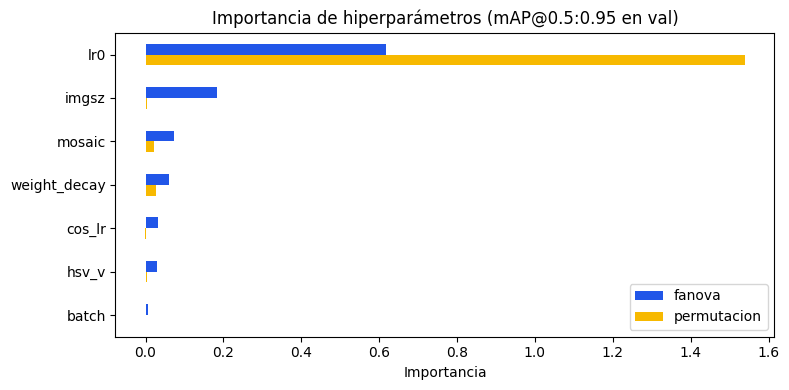

,fanova,permutacion
lr0,0.616363,1.538211
imgsz,0.182555,0.004685
mosaic,0.074392,0.022944
weight_decay,0.059536,0.026504
cos_lr,0.031361,-0.000216
hsv_v,0.030617,0.004816
batch,0.005176,0.000269


In [6]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

PARAMS = ["lr0", "weight_decay", "imgsz", "batch", "mosaic", "hsv_v", "cos_lr"]
X = trials[PARAMS].copy()
X["lr0"], X["weight_decay"] = np.log10(X["lr0"]), np.log10(X["weight_decay"])
X["cos_lr"] = X["cos_lr"].astype(int)
y = trials["map50_95"].values

fanova = optuna.importance.get_param_importances(study, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=SEED))
rf = RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=SEED).fit(X, y)
perm = permutation_importance(rf, X, y, n_repeats=30, random_state=SEED)
ranking = pd.DataFrame({"fanova": pd.Series(fanova), "permutacion": pd.Series(perm.importances_mean, index=PARAMS)}) \
    .sort_values("fanova", ascending=False)
ranking.to_csv(OPT_DIR / "optimizacion_importancia.csv")

fig, ax = plt.subplots(figsize=(8, 4))
ranking.plot.barh(ax=ax, color=["#2156e8", "#f7b900"]); ax.invert_yaxis()
ax.set_xlabel("Importancia"); ax.set_title("Importancia de hiperparámetros (mAP@0.5:0.95 en val)")
fig.tight_layout(); fig.savefig(FIG_DIR / "opt_importancia.png", dpi=160); plt.show()
ranking

## 4. Partial dependence plots
Efecto promedio de cada hiperparámetro sobre el mAP predicho por el sustituto (`lr0` y `weight_decay` en log10).

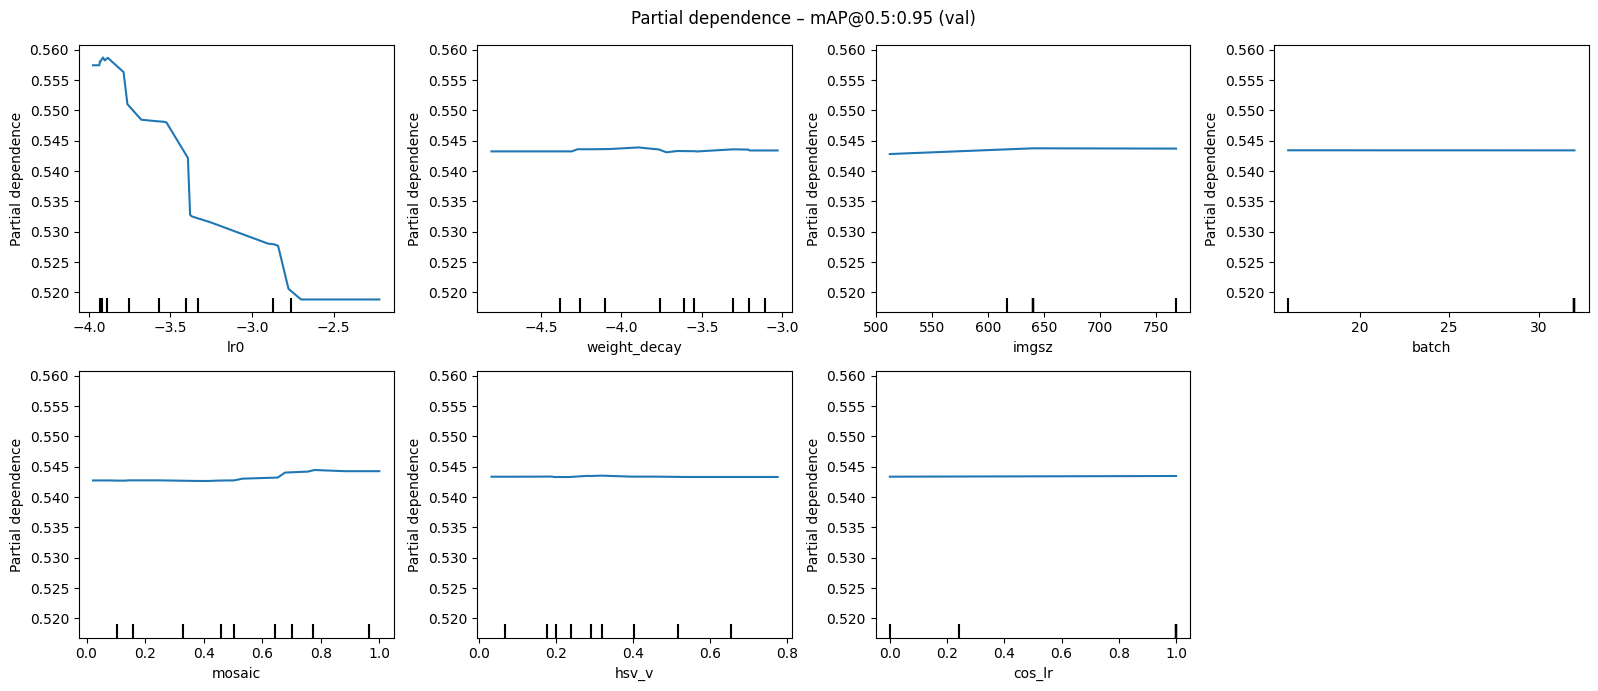

In [7]:
from sklearn.inspection import PartialDependenceDisplay

fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
PartialDependenceDisplay.from_estimator(rf, X, PARAMS, ax=axes[:len(PARAMS)], grid_resolution=30)
axes[-1].axis("off")
fig.suptitle("Partial dependence – mAP@0.5:0.95 (val)"); fig.tight_layout()
fig.savefig(FIG_DIR / "opt_pdp.png", dpi=160); plt.show()

### Interacciones
PDP 2D de los dos pares formados por los tres hiperparámetros más importantes.

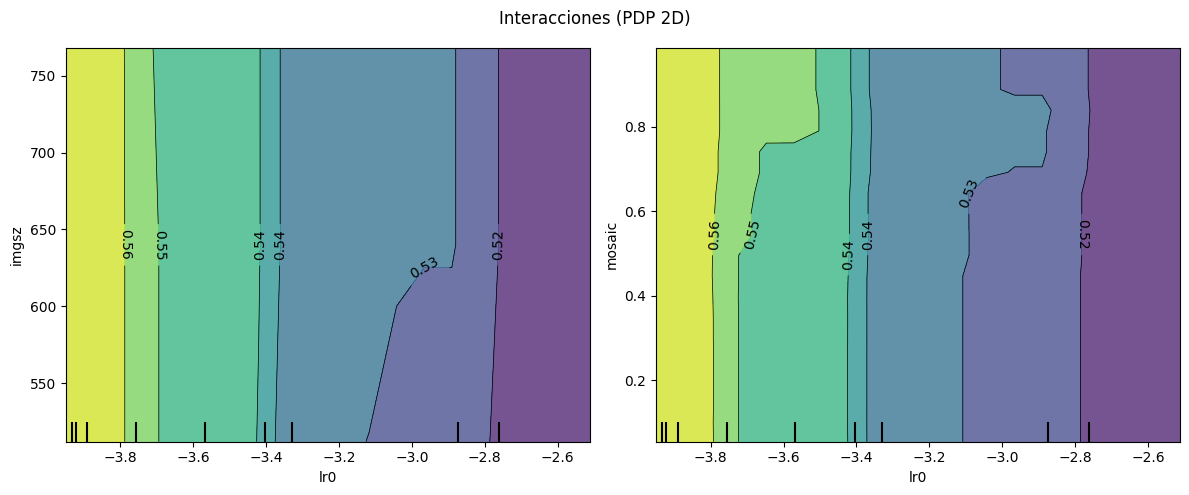

Pares: [('lr0', 'imgsz'), ('lr0', 'mosaic')]


In [8]:
top = list(ranking.index[:3])
pairs = [(top[0], top[1]), (top[0], top[2])]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PartialDependenceDisplay.from_estimator(rf, X, pairs, ax=axes, grid_resolution=20)
fig.suptitle("Interacciones (PDP 2D)"); fig.tight_layout()
fig.savefig(FIG_DIR / "opt_interacciones.png", dpi=160); plt.show()
print("Pares:", pairs)

## 5. Antes / después con el protocolo completo
Se reentrena la mejor configuración con el protocolo del modelo entregado (40 épocas, 100 % de los datos,
paciencia 10) y se compara con la base **en *test***. La base se lee de los pesos ya entrenados (no se reentrena).

In [9]:
BASE_WEIGHTS = WORK_DIR / "experimentos" / f"{RF_PROJECT}-v{RF_VERSION}" / "runs" / "YOLO11_yolo11s_completo" / "weights" / "best.pt"
best = dict(study.best_params)
final_dir = OPT_DIR / "runs" / "final_optimizado"
if not (final_dir / "weights" / "best.pt").exists():
    YOLO("yolo11s.pt").train(data=str(DATA_YAML), epochs=40, patience=10, seed=SEED, deterministic=True,
                             optimizer="AdamW", workers=2, project=str(OPT_DIR / "runs"), name="final_optimizado",
                             exist_ok=True, **best)

def test_metrics(weights, imgsz):
    m = YOLO(str(weights)).val(data=str(DATA_YAML), split="test", imgsz=imgsz, verbose=False, plots=False)
    return {"map50": float(m.box.map50), "map50_95": float(m.box.map), "precision": float(m.box.mp), "recall": float(m.box.mr)}

comparison = pd.DataFrame({
    "base": test_metrics(BASE_WEIGHTS, 640),
    "optimizada": test_metrics(final_dir / "weights" / "best.pt", best["imgsz"]),
}).T
comparison["delta_map50_95"] = comparison["map50_95"] - comparison.loc["base", "map50_95"]
comparison.to_csv(OPT_DIR / "optimizacion_antes_despues.csv")
json.dump({"mejor_config": best, "comparacion_test": comparison.to_dict()},
          open(OPT_DIR / "optimizacion_resumen.json", "w"), indent=2)
comparison

New https://pypi.org/project/ultralytics/8.4.186 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.177 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/datasets/license-plate-recognition-rxg4e-v11/data_abs.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.28861698681111003, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001632740155846879, lrf=0.01, mask_ra

,map50,map50_95,precision,recall,delta_map50_95
base,0.972226,0.692586,0.986663,0.952074,0.000000
optimizada,0.972838,0.703834,0.988249,0.945622,0.011248


## 6. Copiar resultados al repositorio
Descargue estos archivos y súbalos a GitHub (o use `git` desde Colab):

| Archivo en Drive | Destino en el repositorio |
|---|---|
| `optimizacion/optimizacion_*.csv`, `optimizacion_resumen.json` | `results/metrics/` |
| `optimizacion/figuras/opt_*.png` | `results/figures/` |

Luego complete las tablas marcadas con ⏳ en `docs/optimizacion.md`.